In [1]:
from pathlib import Path

import cv2
import pandas as pd
import matplotlib.pyplot as plt

print("OpenCV version:", cv2.__version__)
print("Pandas version:", pd.__version__)
print("Libraries imported successfully.")

OpenCV version: 4.11.0
Pandas version: 2.3.3
Libraries imported successfully.


In [2]:
# Project root
ROOT = Path(r"D:\CrowdTrackAI")

# Select one MOT17 training sequence
SEQUENCE = ROOT / "data" / "raw" / "MOT17" / "train" / "MOT17-02-FRCNN"

IMAGE_DIR = SEQUENCE / "img1"
GT_PATH = SEQUENCE / "gt" / "gt.txt"
SEQINFO_PATH = SEQUENCE / "seqinfo.ini"

# Frame to inspect
FRAME_NUMBER = 100

IMAGE_PATH = IMAGE_DIR / f"{FRAME_NUMBER:06d}.jpg"

print("Sequence exists:", SEQUENCE.exists())
print("Image directory exists:", IMAGE_DIR.exists())
print("Ground truth exists:", GT_PATH.exists())
print("Sequence metadata exists:", SEQINFO_PATH.exists())
print("Selected frame exists:", IMAGE_PATH.exists())

Sequence exists: True
Image directory exists: True
Ground truth exists: True
Sequence metadata exists: True
Selected frame exists: True


In [3]:
print(SEQINFO_PATH.read_text())

[Sequence]
name=MOT17-02-FRCNN
imDir=img1
frameRate=30
seqLength=600
imWidth=1920
imHeight=1080
imExt=.jpg




In [4]:
frame_paths = sorted(IMAGE_DIR.glob("*.jpg"))

print("Total JPG frames:", len(frame_paths))
print("First five frames:")

for path in frame_paths[:5]:
    print(path.name)

Total JPG frames: 600
First five frames:
000001.jpg
000002.jpg
000003.jpg
000004.jpg
000005.jpg


In [5]:
GT_COLUMNS = [
    "frame",
    "id",
    "x",
    "y",
    "width",
    "height",
    "confidence",
    "class_id",
    "visibility",
]

gt = pd.read_csv(
    GT_PATH,
    header=None,
    names=GT_COLUMNS
)

print("Ground-truth shape:", gt.shape)
display(gt.head(10))
print("\nData types:")
print(gt.dtypes)

Ground-truth shape: (30003, 9)


,frame,id,x,y,width,height,confidence,class_id,visibility
0,1,1,912,484,97,109,0,7,1.0
1,2,1,912,484,97,109,0,7,1.0
2,3,1,912,484,97,109,0,7,1.0
3,4,1,912,484,97,109,0,7,1.0
4,5,1,912,484,97,109,0,7,1.0
5,6,1,912,484,97,109,0,7,1.0
6,7,1,912,484,97,109,0,7,1.0
7,8,1,912,484,97,109,0,7,1.0
8,9,1,912,484,97,109,0,7,1.0
9,10,1,912,484,97,109,0,7,1.0



Data types:
frame           int64
id              int64
x               int64
y               int64
width           int64
height          int64
confidence      int64
class_id        int64
visibility    float64
dtype: object


In [6]:
frame_gt = gt[gt["frame"] == FRAME_NUMBER].copy()

print("Frame number:", FRAME_NUMBER)
print("Total annotation rows:", len(frame_gt))

print("\nAnnotation counts by class:")
display(frame_gt["class_id"].value_counts().sort_index().to_frame("count"))

display(frame_gt.head(10))

Frame number: 100
Total annotation rows: 45

Annotation counts by class:


,count
class_id,
1,26
2,3
4,3
7,8
8,2
9,3


,frame,id,x,y,width,height,confidence,class_id,visibility
99,100,1,912,484,97,109,0,7,1.00000
755,100,3,648,439,100,305,1,1,0.78574
1330,100,4,1585,-1,336,578,0,9,0.99359
1930,100,5,1163,441,33,89,0,8,1.00000
2530,100,6,1308,431,34,118,0,8,1.00000
3111,100,7,907,414,30,139,0,9,0.58065
3754,100,9,1053,483,37,110,1,1,0.94784
4354,100,10,1089,484,34,114,1,1,1.00000
4954,100,11,706,486,44,91,0,2,0.00000
5484,100,12,679,492,51,105,0,2,0.00000


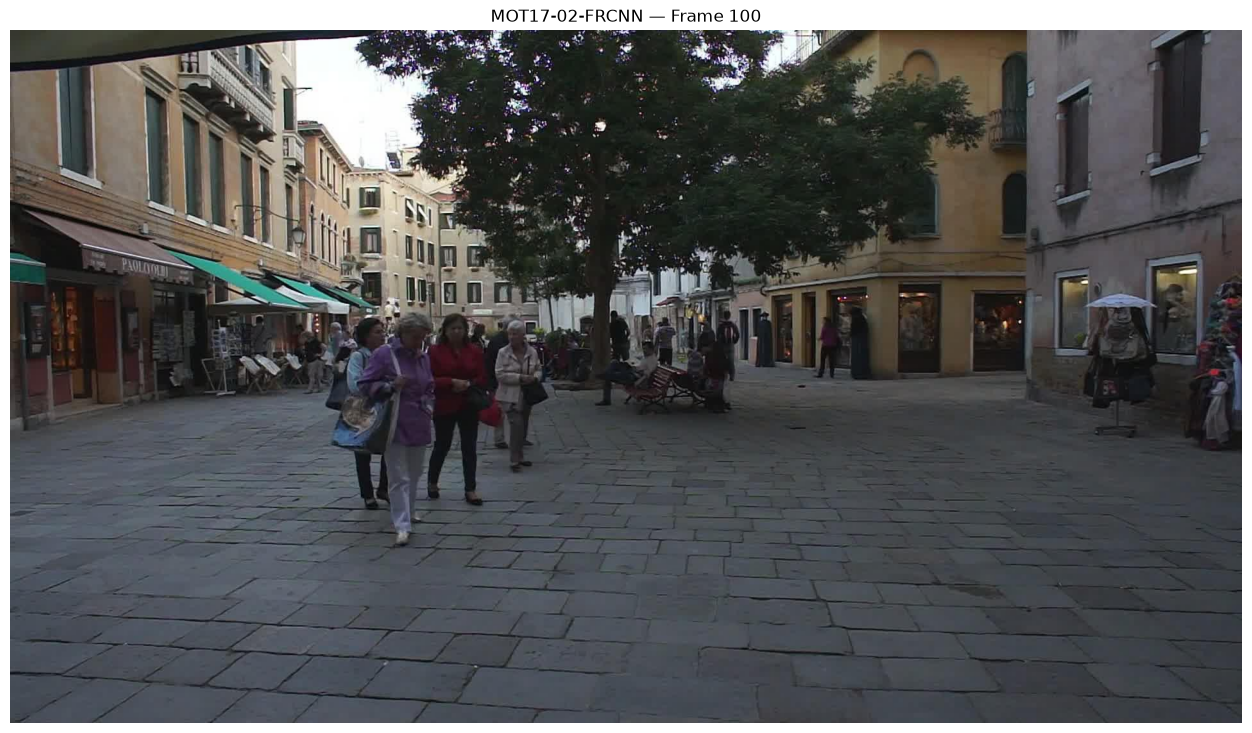

Image dimensions: 1920 x 1080


In [7]:
image = cv2.imread(str(IMAGE_PATH))

if image is None:
    raise FileNotFoundError(f"Could not read image: {IMAGE_PATH}")

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(16, 9))
plt.imshow(image_rgb)
plt.title(f"MOT17-02-FRCNN — Frame {FRAME_NUMBER}")
plt.axis("off")
plt.show()

print("Image dimensions:", image.shape[1], "x", image.shape[0])

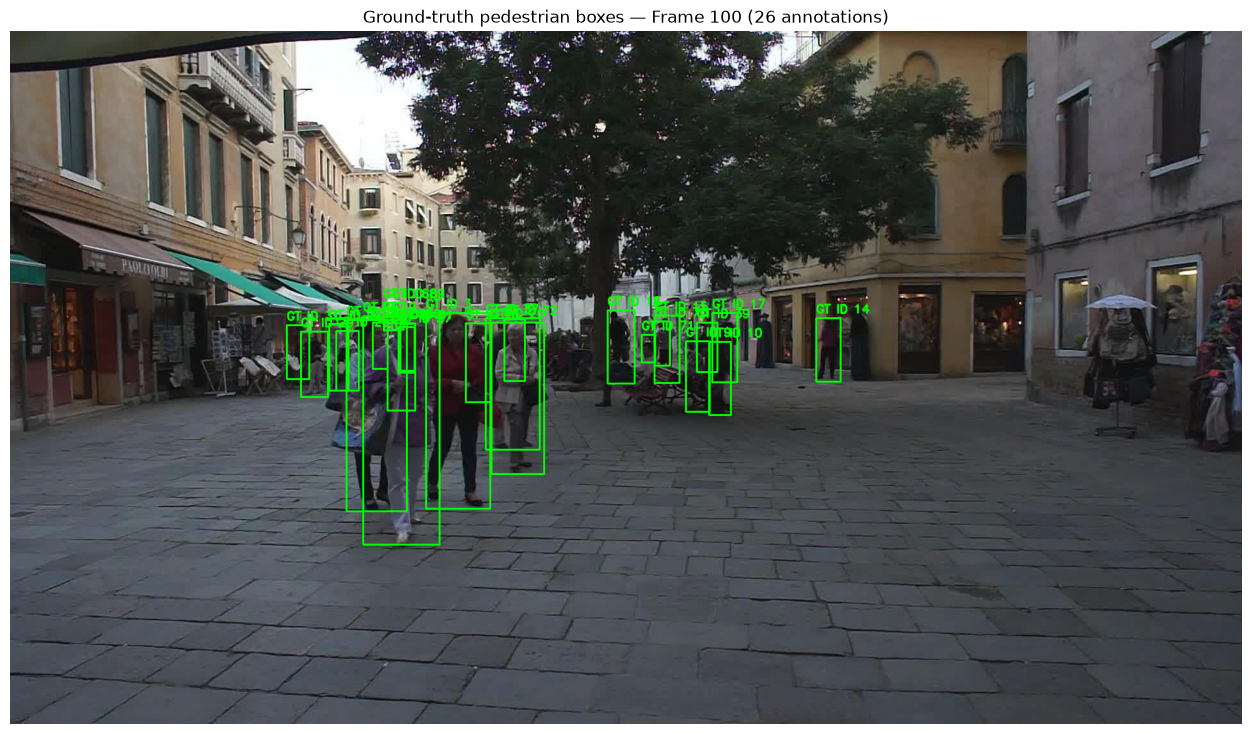

Pedestrian annotations drawn: 26


In [8]:
# MOTChallenge class ID 1 represents a pedestrian.
pedestrians = frame_gt[frame_gt["class_id"] == 1].copy()

annotated = image.copy()
height, width = annotated.shape[:2]

for _, row in pedestrians.iterrows():
    x1 = int(round(row["x"]))
    y1 = int(round(row["y"]))
    x2 = int(round(row["x"] + row["width"]))
    y2 = int(round(row["y"] + row["height"]))

    # Keep coordinates within image boundaries.
    x1 = max(0, min(x1, width - 1))
    y1 = max(0, min(y1, height - 1))
    x2 = max(0, min(x2, width - 1))
    y2 = max(0, min(y2, height - 1))

    if x2 <= x1 or y2 <= y1:
        continue

    track_id = int(row["id"])

    cv2.rectangle(
        annotated,
        (x1, y1),
        (x2, y2),
        (0, 255, 0),
        2
    )

    cv2.putText(
        annotated,
        f"GT ID {track_id}",
        (x1, max(y1 - 8, 20)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.6,
        (0, 255, 0),
        2
    )

annotated_rgb = cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(16, 9))
plt.imshow(annotated_rgb)
plt.title(
    f"Ground-truth pedestrian boxes — Frame {FRAME_NUMBER} "
    f"({len(pedestrians)} annotations)"
)
plt.axis("off")
plt.show()

print("Pedestrian annotations drawn:", len(pedestrians))

In [9]:
OUTPUT_DIR = ROOT / "reports"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_PATH = OUTPUT_DIR / f"gt_frame_{FRAME_NUMBER:06d}.jpg"

success = cv2.imwrite(str(OUTPUT_PATH), annotated)

if not success:
    raise RuntimeError("Failed to save visualization.")

print("Saved to:", OUTPUT_PATH)

Saved to: D:\CrowdTrackAI\reports\gt_frame_000100.jpg
